In [ ]:
!pip install pydicom SimpleITK imageio tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 44.1 MB/s eta 0:00:00


In [ ]:
import os
import csv
import random
import numpy as np
import pandas as pd
import SimpleITK as sitk
import imageio.v2 as imageio
from tqdm.notebook import tqdm

# ============================================================
# 🔧 USER CONFIGURATION — edit PROJECT_ROOT for your own setup
# ============================================================
PROJECT_ROOT = "/content/drive/MyDrive/lung_nodule_classification"

# --- 1. PATH CONFIGURATION ---
# LUNA16 root directory (download from https://luna16.grand-challenge.org/Data/)
LUNA_ROOT = f"{PROJECT_ROOT}/raw_datasets/LUNA16"
LUNA_SUBSETS_DIR = os.path.join(LUNA_ROOT, "subsets")
CANDIDATES_CSV = os.path.join(LUNA_ROOT, "candidates.csv")

# Separate output (to avoid mixing with LIDC/LNDb)
OUTPUT_DIR = f"{PROJECT_ROOT}/extracted_patches/LUNA16"
CLASS_0_DIR = os.path.join(OUTPUT_DIR, "class_0")
os.makedirs(CLASS_0_DIR, exist_ok=True)

# --- 2. PARAMETERS ---
# Goal: balance the ~2400 nodules (LIDC+LNDb)
MAX_SAMPLES_TOTAL = 2500
# Using 4 subsets to get enough variety
SUBSETS_TO_PROCESS = ["subset0", "subset1", "subset2", "subset3"]
PATCH_SIZE = 64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# --- 3. FUNCTIONS ---
def hu_to_uint8(patch, hu_window=(-1000, 400)):
    vmin, vmax = hu_window
    patch = np.clip(patch, vmin, vmax)
    patch = (patch - vmin) / (vmax - vmin + 1e-8)
    return (patch * 255.0).astype(np.uint8)

def get_voxel_coords(world_coords, origin, spacing):
    stretched = np.absolute(world_coords - origin)
    return (stretched / spacing).astype(int)

def extract_2_5d_patch_luna(vol, center_xyz_voxel):
    """2.5D extraction (z-1, z, z+1)"""
    vx, vy, vz = center_xyz_voxel
    D, H, W = vol.shape
    pad = PATCH_SIZE // 2

    if vz < 1 or vz >= D - 1: return None
    if vy < pad or vy >= H - pad: return None
    if vx < pad or vx >= W - pad: return None

    s0 = vol[vz-1, vy-pad:vy+pad, vx-pad:vx+pad]
    s1 = vol[vz,   vy-pad:vy+pad, vx-pad:vx+pad]
    s2 = vol[vz+1, vy-pad:vy+pad, vx-pad:vx+pad]
    return np.stack([s0, s1, s2], axis=-1)


In [ ]:
# --- 4. EXECUTION ---
print(f"🚀 Source: {LUNA_SUBSETS_DIR}")
print(f"📂 Destination: {OUTPUT_DIR}")
print(f"🎯 Target: {MAX_SAMPLES_TOTAL} Non-Nodules")

if not os.path.exists(CANDIDATES_CSV):
    print(f"❌ ERROR: candidates.csv not found in {LUNA_ROOT}")
else:
    print("⏳ Optimized reading of candidates CSV...")
    # Read in chunks to avoid saturating RAM
    df_chunks = pd.read_csv(CANDIDATES_CSV, chunksize=50000)
    df_class0 = pd.concat([chunk[chunk['class'] == 0] for chunk in df_chunks])
    print(f"👉 Total 'Non-Nodule' candidates available: {len(df_class0)}")

    # Metadata log
    log_path = os.path.join(OUTPUT_DIR, "metadata_luna16.csv")
    fieldnames = ["patch_path", "seriesuid", "class_label", "coord_z", "coord_y", "coord_x"]

    if not os.path.exists(log_path):
        with open(log_path, "w", newline="") as f:
            csv.DictWriter(f, fieldnames=fieldnames).writeheader()

    total_extracted = 0

    with open(log_path, "a", newline="") as csvfile:
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

        for subset in SUBSETS_TO_PROCESS:
            if total_extracted >= MAX_SAMPLES_TOTAL: break

            subset_path = os.path.join(LUNA_SUBSETS_DIR, subset)
            if not os.path.exists(subset_path):
                print(f"⚠️ {subset} not found, skipping.")
                continue

            print(f"🔍 Processing {subset}...")
            mhd_files = [f for f in os.listdir(subset_path) if f.endswith(".mhd")]
            random.shuffle(mhd_files) # Shuffle for variety

            for mhd_file in tqdm(mhd_files, desc=f"Images {subset}"):
                if total_extracted >= MAX_SAMPLES_TOTAL: break

                series_uid = mhd_file.replace(".mhd", "")

                # Filter candidates for this patient
                candidates = df_class0[df_class0['seriesuid'] == series_uid]
                if candidates.empty: continue

                # Take 2 random candidates per patient (maximum diversity)
                candidates_sample = candidates.sample(n=min(len(candidates), 2))

                try:
                    img_path = os.path.join(subset_path, mhd_file)
                    itk_img = sitk.ReadImage(img_path)
                    vol = sitk.GetArrayFromImage(itk_img)
                    origin = np.array(itk_img.GetOrigin())
                    spacing = np.array(itk_img.GetSpacing())

                    for _, row in candidates_sample.iterrows():
                        if total_extracted >= MAX_SAMPLES_TOTAL: break

                        world = np.array([row['coordX'], row['coordY'], row['coordZ']])
                        v_coords = get_voxel_coords(world, origin, spacing)

                        patch = extract_2_5d_patch_luna(vol, v_coords)

                        if patch is not None:
                            fname = f"{series_uid}_x{v_coords[0]}.png"
                            out_path = os.path.join(CLASS_0_DIR, fname)

                            imageio.imwrite(out_path, hu_to_uint8(patch))

                            writer.writerow({
                                "patch_path": out_path, "seriesuid": series_uid,
                                "class_label": 0,
                                "coord_z": row['coordZ'], "coord_y": row['coordY'], "coord_x": row['coordX']
                            })
                            total_extracted += 1

                except Exception: continue

    print(f"✅ Done! {total_extracted} images saved in:\n{OUTPUT_DIR}")


🚀 Source: /content/drive/MyDrive/lung_nodule_classification/raw_datasets/LUNA16/subsets
📂 Destination: /content/drive/MyDrive/lung_nodule_classification/extracted_patches/LUNA16
🎯 Target: 2500 Non-Nodules
⏳ Optimized reading of candidates CSV...
👉 Total 'Non-Nodule' candidates available: 549714
🔍 Processing subset0...


Images subset0:   0%|          | 0/89 [00:00<?, ?it/s]

🔍 Processing subset1...


Images subset1:   0%|          | 0/89 [00:00<?, ?it/s]

🔍 Processing subset2...


Images subset2:   0%|          | 0/89 [00:00<?, ?it/s]

🔍 Processing subset3...


Images subset3:   0%|          | 0/89 [00:00<?, ?it/s]

✅ Done! 711 images saved in:
/content/drive/MyDrive/lung_nodule_classification/extracted_patches/LUNA16


In [ ]:
# --- 1. CONFIGURATION ---
LUNA_SUBSETS_DIR = f"{PROJECT_ROOT}/raw_datasets/LUNA16/subsets"
CANDIDATES_CSV = f"{PROJECT_ROOT}/raw_datasets/LUNA16/candidates.csv"
OUTPUT_DIR = f"{PROJECT_ROOT}/extracted_patches/LUNA16"  # NOTE: fixed — originally pointed to a different, unrelated "2025_2026" folder than Cell 1 and every downstream notebook
CLASS_0_DIR = os.path.join(OUTPUT_DIR, "class_0")
LOG_PATH = os.path.join(OUTPUT_DIR, "metadata_luna16.csv")

# --- 2. CONTINUATION PARAMETERS ---
TARGET_TOTAL = 2500  # Final target

# List ONLY the new subsets here
# (Do NOT include 0, 1, 3 since they are already done)
SUBSETS_TO_ADD = ["subset4", "subset5"]

# Slightly increase the rate to make up the shortfall with these new folders
SAMPLES_PER_PATIENT = 15
PATCH_SIZE = 64


In [ ]:
# --- 3. CURRENT STATE CHECK ---
current_count = 0
if os.path.exists(LOG_PATH):
    # Count how many lines we already have (minus the header)
    with open(LOG_PATH, "r") as f:
        current_count = sum(1 for line in f) - 1
    print(f"✅ Already done: {current_count} images.")
else:
    print("⚠️ No existing file found, starting from 0.")

needed = TARGET_TOTAL - current_count
print(f"🎯 Remaining to extract: {needed} images from {SUBSETS_TO_ADD}")

if needed <= 0:
    print("🎉 Target already reached! No need to continue.")
else:
    # --- 4. EXECUTION (APPEND MODE) ---

    # Load candidates CSV
    print("⏳ Loading candidates...")
    df_chunks = pd.read_csv(CANDIDATES_CSV, chunksize=50000)
    df_class0 = pd.concat([chunk[chunk['class'] == 0] for chunk in df_chunks])

    newly_extracted = 0

    # Open in 'a' (APPEND) mode to add at the end
    with open(LOG_PATH, "a", newline="") as csvfile:
        fieldnames = ["patch_path", "seriesuid", "class_label", "coord_z", "coord_y", "coord_x"]
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

        # No writeheader() since the header already exists!

        for subset in SUBSETS_TO_ADD:
            if newly_extracted >= needed: break

            subset_path = os.path.join(LUNA_SUBSETS_DIR, subset)
            if not os.path.exists(subset_path):
                print(f"⚠️ {subset} not found, skipping.")
                continue

            print(f"⚡ Processing {subset}...")
            mhd_files = [f for f in os.listdir(subset_path) if f.endswith(".mhd")]
            random.shuffle(mhd_files)

            for mhd_file in tqdm(mhd_files, desc=f"Adding from {subset}"):
                if newly_extracted >= needed: break

                series_uid = mhd_file.replace(".mhd", "")
                candidates = df_class0[df_class0['seriesuid'] == series_uid]
                if candidates.empty: continue

                # Sampling
                n_take = min(len(candidates), SAMPLES_PER_PATIENT)
                candidates_sample = candidates.sample(n=n_take)

                try:
                    img_path = os.path.join(subset_path, mhd_file)
                    itk_img = sitk.ReadImage(img_path)
                    vol = sitk.GetArrayFromImage(itk_img)
                    origin = np.array(itk_img.GetOrigin())
                    spacing = np.array(itk_img.GetSpacing())

                    # Local extraction function
                    def extract_local(vol, center_xyz_voxel):
                        vx, vy, vz = center_xyz_voxel
                        D, H, W = vol.shape
                        pad = 64 // 2
                        if vz < 1 or vz >= D - 1: return None
                        if vy < pad or vy >= H - pad: return None
                        if vx < pad or vx >= W - pad: return None
                        s0 = vol[vz-1, vy-pad:vy+pad, vx-pad:vx+pad]
                        s1 = vol[vz,   vy-pad:vy+pad, vx-pad:vx+pad]
                        s2 = vol[vz+1, vy-pad:vy+pad, vx-pad:vx+pad]
                        return np.stack([s0, s1, s2], axis=-1)

                    def hu_to_uint8(patch):
                        patch = np.clip(patch, -1000, 400)
                        patch = (patch + 1000) / 1400
                        return (patch * 255.0).astype(np.uint8)

                    for _, row in candidates_sample.iterrows():
                        if newly_extracted >= needed: break

                        world = np.array([row['coordX'], row['coordY'], row['coordZ']])
                        # Coordinate conversion
                        stretched = np.absolute(world - origin)
                        v_coords = (stretched / spacing).astype(int)

                        patch = extract_local(vol, v_coords)

                        if patch is not None:
                            fname = f"{series_uid}_x{v_coords[0]}_z{v_coords[2]}.png"
                            out_path = os.path.join(CLASS_0_DIR, fname)

                            if not os.path.exists(out_path):
                                imageio.imwrite(out_path, hu_to_uint8(patch))

                                writer.writerow({
                                    "patch_path": out_path, "seriesuid": series_uid, "class_label": 0,
                                    "coord_z": row['coordZ'], "coord_y": row['coordY'], "coord_x": row['coordX']
                                })
                                newly_extracted += 1
                except: continue

    print(f"✅ DONE! Added: {newly_extracted} images.")
    print(f"📊 New total: {current_count + newly_extracted} / {TARGET_TOTAL}")


✅ Already done: 711 images.
🎯 Remaining to extract: 1789 images from ['subset4', 'subset5']
⏳ Loading candidates...
⚡ Processing subset4...


Adding from subset4:   0%|          | 0/89 [00:00<?, ?it/s]

⚡ Processing subset5...


Adding from subset5:   0%|          | 0/89 [00:00<?, ?it/s]

✅ DONE! Added: 1789 images.
📊 New total: 2500 / 2500


📊 Total LUNA16 images available: 2500
📂 Folder: /content/drive/MyDrive/lung_nodule_classification/extracted_patches/LUNA16


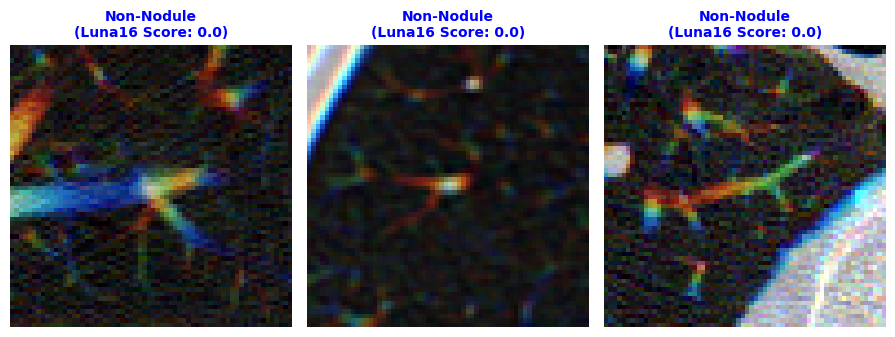

In [ ]:
# ==========================================
# LUNA16 VISUALIZATION (Class 0)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

# The folder where we extracted (Append or Normal mode)
LUNA_OUTPUT_DIR = f"{PROJECT_ROOT}/extracted_patches/LUNA16"  # NOTE: fixed, see Cell 4/7 comment
csv_path = os.path.join(LUNA_OUTPUT_DIR, "metadata_luna16.csv")

if os.path.exists(csv_path):
    # Load
    df = pd.read_csv(csv_path)

    if len(df) == 0:
        print("⚠️ The CSV file is currently empty.")
    else:
        print(f"📊 Total LUNA16 images available: {len(df)}")
        print(f"📂 Folder: {LUNA_OUTPUT_DIR}")

        # Select 5 random images
        n_samples = min(len(df), 3)
        sample = df.sample(n=n_samples)

        plt.figure(figsize=(15, 4))

        for i, (_, row) in enumerate(sample.iterrows()):
            img_path = row['patch_path']

            plt.subplot(1, 5, i+1)

            if os.path.exists(img_path):
                # Read image
                img = cv2.imread(img_path)
                # Convert BGR -> RGB (Matplotlib displays in RGB)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                plt.imshow(img)

                # Title (Non-Nodule)
                plt.title(f"Non-Nodule\n(Luna16 Score: 0.0)",
                          color='blue', fontweight='bold', fontsize=10)
                plt.axis('off')
            else:
                plt.text(0.5, 0.5, "Missing image", ha='center')
                plt.axis('off')

        plt.tight_layout()
        plt.show()

else:
    print(f"❌ Metadata file not found: {csv_path}")
    print("Check that the extraction has finished.")


In [ ]:
# =========================================================
# STEP 2: LARGE-SCALE LUNA16 EXTRACTION (Target 9600)
# =========================================================
import os
import csv
import random
import numpy as np
import pandas as pd
import SimpleITK as sitk
import imageio.v2 as imageio
from tqdm.notebook import tqdm

# --- CONFIGURATION ---
LUNA_SUBSETS_DIR = f"{PROJECT_ROOT}/raw_datasets/LUNA16/subsets"
CANDIDATES_CSV = f"{PROJECT_ROOT}/raw_datasets/LUNA16/candidates.csv"
OUTPUT_DIR = f"{PROJECT_ROOT}/extracted_patches/LUNA16"  # NOTE: fixed, see Cell 4 comment
CLASS_0_DIR = os.path.join(OUTPUT_DIR, "class_0")
LOG_PATH = os.path.join(OUTPUT_DIR, "metadata_luna16.csv")

# 🎯 NEW LARGE-SCALE TARGET
TARGET_TOTAL = 9600

# Add all available subsets to reach it
SUBSETS_TO_SCAN = ["subset6", "subset7","subset8","subset9"]
# If you don't have 6 and 7, the script will skip them - add the ones you have!

SAMPLES_PER_PATIENT = 50 # Increased since we need a lot of images
PATCH_SIZE = 64

# --- CHECK ---
current_count = 0
if os.path.exists(LOG_PATH):
    with open(LOG_PATH, "r") as f:
        current_count = sum(1 for line in f) - 1
    print(f"✅ Current LUNA16: {current_count} images.")
else:
    print("⚠️ Starting from 0.")

needed = TARGET_TOTAL - current_count
print(f"🎯 Missing: {needed} images to reach balance.")

if needed > 0:
    # --- EXTRACTION ---
    print("⏳ Reading CSV...")
    df_chunks = pd.read_csv(CANDIDATES_CSV, chunksize=50000)
    df_class0 = pd.concat([chunk[chunk['class'] == 0] for chunk in df_chunks])

    newly_extracted = 0

    with open(LOG_PATH, "a", newline="") as csvfile:
        fieldnames = ["patch_path", "seriesuid", "class_label", "coord_z", "coord_y", "coord_x"]
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

        for subset in SUBSETS_TO_SCAN:
            if newly_extracted >= needed: break

            subset_path = os.path.join(LUNA_SUBSETS_DIR, subset)
            if not os.path.exists(subset_path): continue

            print(f"⚡ Processing {subset}...")
            mhd_files = [f for f in os.listdir(subset_path) if f.endswith(".mhd")]
            random.shuffle(mhd_files)

            for mhd_file in tqdm(mhd_files, desc=f"Mining {subset}"):
                if newly_extracted >= needed: break

                series_uid = mhd_file.replace(".mhd", "")
                candidates = df_class0[df_class0['seriesuid'] == series_uid]
                if candidates.empty: continue

                n_take = min(len(candidates), SAMPLES_PER_PATIENT)
                candidates_sample = candidates.sample(n=n_take)

                try:
                    img_path = os.path.join(subset_path, mhd_file)
                    itk_img = sitk.ReadImage(img_path)
                    vol = sitk.GetArrayFromImage(itk_img)
                    origin = np.array(itk_img.GetOrigin())
                    spacing = np.array(itk_img.GetSpacing())

                    # Small extraction function
                    def get_patch(v, c):
                        pad=32
                        if c[2]<1 or c[2]>=v.shape[0]-1 or c[1]<pad or c[1]>=v.shape[1]-pad or c[0]<pad or c[0]>=v.shape[2]-pad: return None
                        return np.stack([v[c[2]-1, c[1]-pad:c[1]+pad, c[0]-pad:c[0]+pad],
                                         v[c[2],   c[1]-pad:c[1]+pad, c[0]-pad:c[0]+pad],
                                         v[c[2]+1, c[1]-pad:c[1]+pad, c[0]-pad:c[0]+pad]], axis=-1)

                    for _, row in candidates_sample.iterrows():
                        if newly_extracted >= needed: break
                        world = np.array([row['coordX'], row['coordY'], row['coordZ']])
                        v_coords = (np.absolute(world - origin) / spacing).astype(int)

                        patch = get_patch(vol, v_coords)
                        if patch is not None:
                            fname = f"{series_uid}_x{v_coords[0]}_z{v_coords[2]}.png"
                            out_path = os.path.join(CLASS_0_DIR, fname)
                            if not os.path.exists(out_path):
                                p_uint8 = ((np.clip(patch, -1000, 400)+1000)/1400*255).astype(np.uint8)
                                imageio.imwrite(out_path, p_uint8)
                                writer.writerow({"patch_path": out_path, "seriesuid": series_uid, "class_label": 0, "coord_z": row['coordZ'], "coord_y": row['coordY'], "coord_x": row['coordX']})
                                newly_extracted += 1
                except: continue

    print(f"✅ DONE! Total LUNA16: {current_count + newly_extracted}")


✅ Current LUNA16: 2500 images.
🎯 Missing: 7100 images to reach balance.
⏳ Reading CSV...
⚡ Processing subset6...


Mining subset6:   0%|          | 0/89 [00:00<?, ?it/s]

⚡ Processing subset7...


Mining subset7:   0%|          | 0/89 [00:00<?, ?it/s]

✅ DONE! Total LUNA16: 9600
